# Mutation Lollipop Plot

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Scientific:* Specialised plots for statistics and scientific research: survival, effect sizes, agreement, omics, study flow and longitudinal data.

## Design purpose

Draws a protein as a horizontal bar with its functional domains, and places a lollipop at each mutated amino acid position. Stem height is the number of patients with that mutation and head color is the mutation type, so hotspots and their location relative to domains are visible at once.

## When to use

- Show where mutations fall along one gene or protein in a cohort
- Identify hotspots and whether they cluster in a functional domain
- Contrast hotspot mutations (oncogene pattern) with scattered truncating mutations (tumour-suppressor pattern)

## Avoid when

- Comparing many genes (use an oncoprint or frequency bars)
- Mutations are too dense to separate at the plotted resolution (bin positions or zoom into a domain)

## Alternatives

- OncoPrint
- Histogram of mutation positions

## Design tips

- Label only the top few hotspots with their amino-acid change
- Use distinct, consistent colors for mutation classes and keep domain colors muted
- Give the protein length and the cohort size so readers can judge the counts

## Example

Somatic mutations in a TP53-like protein (393 amino acids) across 300 synthetic tumours, with hotspots in the DNA-binding domain.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.patches import FancyBboxPatch

### Data

In [2]:
rng = np.random.default_rng(53)
length = 393
domains = [("Transactivation", 1, 61), ("DNA-binding", 102, 292), ("Tetramerization", 325, 356)]
hotspots = {175: ("R175H", 22), 245: ("G245S", 9), 248: ("R248Q", 18), 273: ("R273H", 20), 282: ("R282W", 10),
            220: ("Y220C", 7)}
rows = [{"pos": p, "change": name, "type": "Missense", "count": c} for p, (name, c) in hotspots.items()]
for p in rng.integers(100, 300, 40):                        # sporadic missense, mostly in DNA-binding domain
    rows.append({"pos": int(p), "change": f"p.{p}", "type": "Missense", "count": int(rng.integers(1, 4))})
for p in rng.integers(1, length, 28):                      # truncating mutations anywhere
    rows.append({"pos": int(p), "change": f"p.{p}*", "type": "Truncating", "count": int(rng.integers(1, 4))})
for p in rng.integers(1, length, 8):
    rows.append({"pos": int(p), "change": f"p.{p}del", "type": "In-frame indel", "count": 1})
muts = pd.DataFrame(rows).groupby(["pos", "type"], as_index=False).agg(count=("count", "sum"), change=("change", "first"))
muts.sort_values("count", ascending=False).head()

,pos,type,count,change
27,175,Missense,22,R175H
63,273,Missense,20,R273H
51,248,Missense,19,R248Q
68,282,Missense,10,R282W
49,245,Missense,9,G245S


### Plot

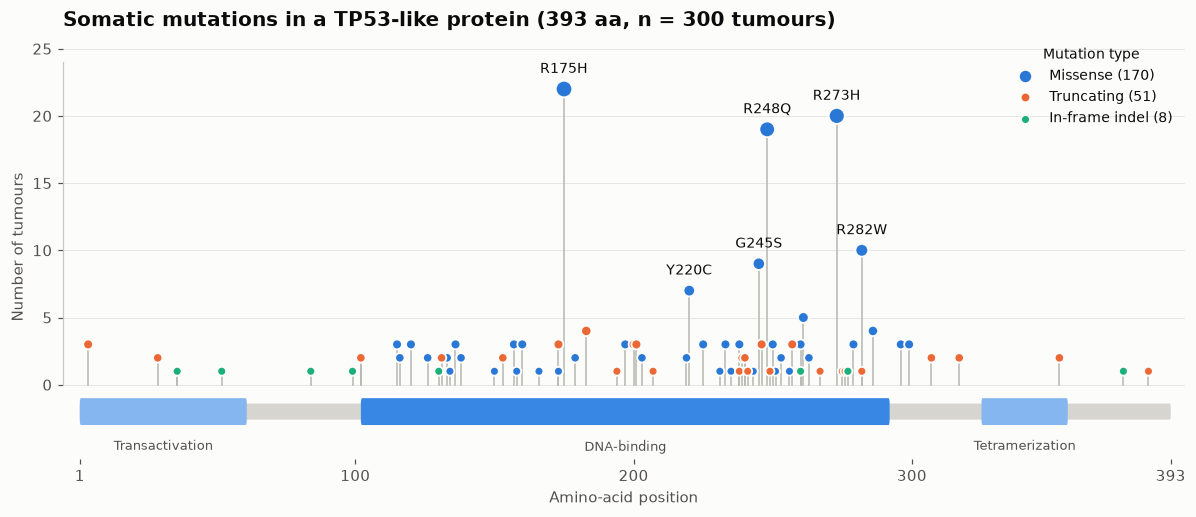

In [3]:
type_color = {"Missense": PALETTE[0], "Truncating": PALETTE[1], "In-frame indel": PALETTE[2]}
fig, ax = plt.subplots(figsize=(11, 4.8))
for _, r in muts.iterrows():
    ax.plot([r["pos"], r["pos"]], [0, r["count"]], color="#b8b7b1", linewidth=1, zorder=1)
for t, col in type_color.items():
    sub = muts[muts["type"] == t]
    ax.scatter(sub["pos"], sub["count"], s=30 + sub["count"] * 4, color=col, edgecolor="#fcfcfb",
               linewidth=1.2, zorder=3, label=f"{t} ({sub['count'].sum()})")
for p, (name, c) in hotspots.items():
    ax.text(p, muts.loc[muts["pos"] == p, "count"].max() + 1.2, name, ha="center", fontsize=9, color="#0b0b0b")
# protein backbone and domains (drawn below zero)
ax.add_patch(FancyBboxPatch((1, -2.6), length - 1, 1.2, boxstyle="round,pad=0,rounding_size=0.3",
                            color="#d6d5d0", linewidth=0))
for (name, s, e), col in zip(domains, ["#86b6ef", "#3987e5", "#86b6ef"]):
    ax.add_patch(FancyBboxPatch((s, -3.0), e - s, 2.0, boxstyle="round,pad=0,rounding_size=0.4", color=col, linewidth=0))
    ax.text((s + e) / 2, -4.1, name, ha="center", va="top", fontsize=8.5, color="#52514e")
ax.set_xlim(-5, length + 5)
ax.set_ylim(-5.5, muts["count"].max() + 4)
ax.spines["bottom"].set_visible(False)
ax.set_yticks(range(0, int(muts["count"].max()) + 5, 5))
ax.spines["left"].set_bounds(0, muts["count"].max() + 2)
ax.set_ylabel("Number of tumours")
ax.set_xlabel("Amino-acid position")
ax.set_xticks([1, 100, 200, 300, length])
ax.grid(axis="x", visible=False)
ax.set_title(f"Somatic mutations in a TP53-like protein ({length} aa, n = 300 tumours)")
ax.legend(loc="upper right", title="Mutation type", fontsize=9, title_fontsize=9)
fig.tight_layout()
plt.show()

## How to read it

Tall lollipops are recurrent hotspots, and almost all of them sit in the DNA-binding domain. Truncating mutations (orange) are scattered along the whole protein, the classic pattern of a tumour-suppressor gene.

---
Standalone script: [`mutation_lollipop.py`](mutation_lollipop.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)